# Wind forecast accuracy for day-ahead decisions: January 2026

Exploratory analysis behind the app. It uses the **same service code as the API**
(`backend/app/services`), so the numbers here match what the app shows.

**Question 1:** which wind forecast did the trading team have when they placed their day-ahead
bids, and **question 2:** how wrong were those forecasts?

- **Data:** Elexon BMRS `FUELHH` (fuelType `WIND`, half-hourly actual generation) and `WINDFOR`
  (hourly forecasts, ~8 publishes/day). Nothing else.
- **Scope:** purchase decisions made 1–31 Jan 2026, i.e. delivery days 2 Jan – 1 Feb 2026.
- **Decision-time forecast:** the latest WINDFOR publish at or before the day-ahead gate closure
  on D‑1 (default 09:50 UK, N2EX; 09:20 UK, EPEX, is compared below).
- **Error convention:** `error = actual − forecast`. Negative = less wind than forecast
  (a shortfall the buyer must cover later).

In [1]:
import sys
from datetime import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "backend"))

from app.config import settings
from app.repository.snapshot import get_snapshot
from app.services.metrics import (
    align, breakdown, bucket, compute_metrics, histogram, local_date, local_hour,
)
from app.services.selection import decision_forecasts, select_forecast_at_cutoff

pd.set_option("display.precision", 0)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

snapshot = get_snapshot()
actuals, forecasts = snapshot.actuals, snapshot.forecasts
delivery_days = pd.date_range(settings.delivery_first_day, settings.delivery_last_day).date
GATE = time(9, 50)

## 1. Data overview and quality

In [2]:
quality = snapshot.metadata["quality"]
pd.DataFrame(
    {
        "rows": [quality["actuals"]["rows"], quality["forecasts"]["rows"]],
        "min MW": [quality["actuals"]["min_mw"], quality["forecasts"]["min_mw"]],
        "max MW": [quality["actuals"]["max_mw"], quality["forecasts"]["max_mw"]],
        "negative": [quality["actuals"]["negative_values"], quality["forecasts"]["negative_values"]],
    },
    index=["actuals (FUELHH)", "forecasts (WINDFOR)"],
)

,rows,min MW,max MW,negative
actuals (FUELHH),1488,1695,17805,0
forecasts (WINDFOR),14287,2292,21353,0


In [3]:
print("Missing actual half-hours:", quality["actuals"]["missing_start_times"])
print("Forecast publishes:", quality["forecasts"]["publishes"],
      "from", quality["forecasts"]["first_publish"], "to", quality["forecasts"]["last_publish"])
print("Off-schedule (late) publishes:", quality["forecasts"]["off_schedule_publishes"])
print("Delivery hours with no forecast at all:", quality["forecasts"]["target_hours_without_any_forecast"])

Missing actual half-hours: []
Forecast publishes: 256 from 2025-12-31T02:30:00Z to 2026-01-31T22:30:00Z
Off-schedule (late) publishes: ['2026-01-15T12:25:00Z']
Delivery hours with no forecast at all: []


Actuals are complete and every delivery hour has at least one forecast. One publish was late
(the 11:30 slot on 15 Jan arrived at 12:25). Selection uses the real `publishTime`, so a cutoff
of 12:00 that day correctly falls back to the 09:30 forecast.

**Publish pattern.** Every publish made on day X covers a fixed window, X‑1 21:00 → X+2 21:00 UTC,
so the decision-time forecast always covers the whole delivery day. Lead times run from 14.5h
(00:00) to 37.5h (23:00) at a 09:50 cutoff.

In [4]:
publish_slots = forecasts["publish_time"].drop_duplicates().dt.strftime("%H:%M").value_counts().sort_index()
publish_slots.to_frame("publishes in window")

,publishes in window
publish_time,
02:30,32
04:30,32
07:30,32
09:30,32
11:30,31
12:25,1
15:30,32
18:30,32
22:30,32


## 2. What the trader saw: one delivery day

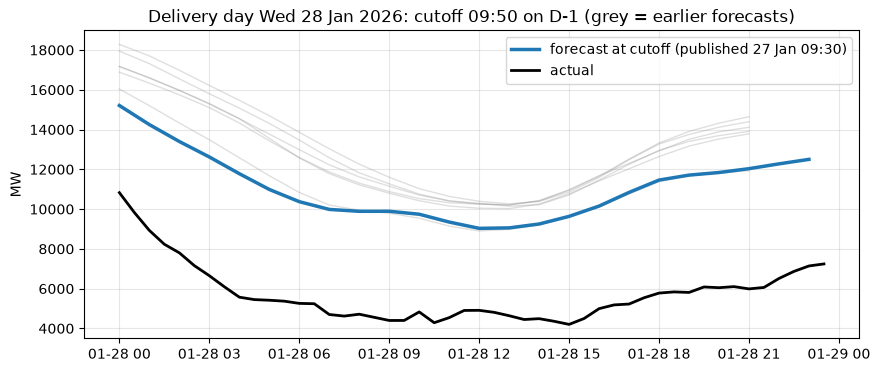

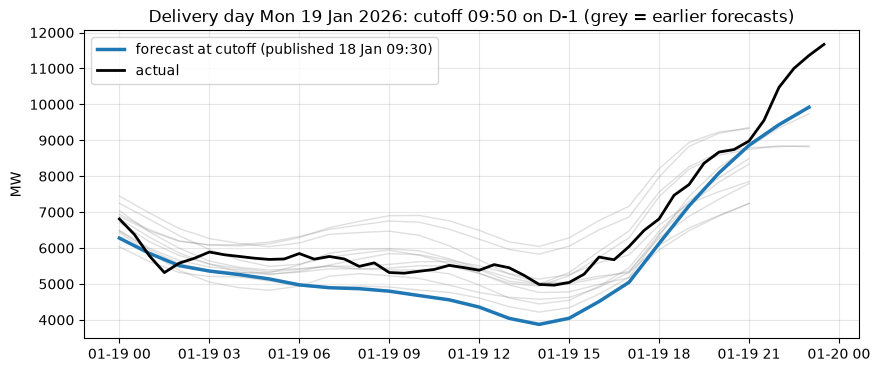

In [5]:
def plot_day(day, cutoff=GATE):
    chosen = select_forecast_at_cutoff(forecasts, day, cutoff)
    start, end = chosen.forecast["start_time"].min(), chosen.forecast["start_time"].max()
    day_actuals = actuals[(actuals["start_time"] >= start) & (actuals["start_time"] <= end + pd.Timedelta("30min"))]
    earlier = forecasts[(forecasts["publish_time"] < chosen.publish_time)
                        & forecasts["start_time"].between(start, end)]
    fig, ax = plt.subplots()
    for _, vintage in earlier.groupby("publish_time"):
        ax.plot(vintage["start_time"], vintage["generation_mw"], color="grey", alpha=0.25, lw=1)
    ax.plot(chosen.forecast["start_time"], chosen.forecast["forecast_mw"], lw=2.5,
            label=f"forecast at cutoff (published {chosen.publish_time:%d %b %H:%M})")
    ax.plot(day_actuals["start_time"], day_actuals["generation_mw"], color="black", lw=2, label="actual")
    ax.set_title(f"Delivery day {day:%a %d %b %Y}: cutoff {cutoff:%H:%M} on D-1 (grey = earlier forecasts)")
    ax.set_ylabel("MW")
    ax.legend()
    plt.show()

plot_day(pd.Timestamp("2026-01-28").date())  # worst day
plot_day(pd.Timestamp("2026-01-19").date())  # best day

## 3. Headline accuracy of the decision-time forecast

In [6]:
def decision_pairs(cutoff):
    return align(decision_forecasts(forecasts, delivery_days, cutoff), actuals)

pairs = decision_pairs(GATE)
summary = pd.DataFrame(
    {f"{c:%H:%M}": vars(compute_metrics(decision_pairs(c))) for c in (time(9, 50), time(9, 20))}
)
summary

,09:50,09:20
count,744,744
mae_mw,1996,2022
rmse_mw,2499,2497
bias_mw,-1728,-1746
wape_pct,18,18
p10_mw,-4184,-4154
p50_mw,-1506,-1582
p90_mw,503,426
max_shortfall_mw,6857,6894
max_surplus_mw,3967,3389


In [7]:
m = compute_metrics(pairs)
print(f"Mean actual {pairs.actual_mw.mean():,.0f} MW vs mean forecast {pairs.forecast_mw.mean():,.0f} MW")
print(f"In 90% of hours actual wind was no more than {m.shortfall_buffer_mw:,.0f} MW below forecast "
      f"(the P10 shortfall buffer).")

Mean actual 11,286 MW vs mean forecast 13,013 MW
In 90% of hours actual wind was no more than 4,184 MW below forecast (the P10 shortfall buffer).


- Typical error (MAE) is ~2.0 GW, **about 18% of actual generation (WAPE)**.
- The error is **strongly one-sided**: on average actual wind came in **~1.7 GW below forecast**,
  and only 10% of hours beat the forecast by more than ~0.5 GW.
- For procurement: holding **~4.2 GW** of cover against the forecast would have covered the wind
  shortfall in 90% of hours.
- 09:50 vs 09:20 gate: the 2h-fresher forecast is only marginally better (~1%).

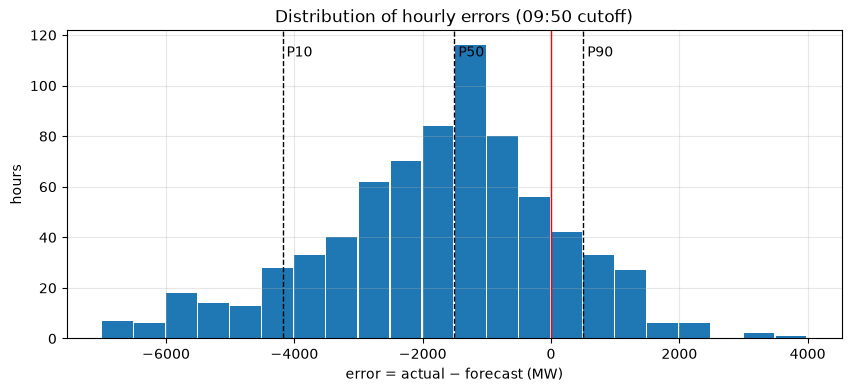

In [8]:
bins = histogram(pairs["error_mw"], bin_width_mw=500)
fig, ax = plt.subplots()
ax.bar(bins["left_mw"], bins["count"], width=480, align="edge")
for q, label in ((m.p10_mw, "P10"), (m.p50_mw, "P50"), (m.p90_mw, "P90")):
    ax.axvline(q, color="black", ls="--", lw=1)
    ax.text(q, ax.get_ylim()[1] * 0.95, f" {label}", va="top")
ax.axvline(0, color="red", lw=1)
ax.set_xlabel("error = actual − forecast (MW)"); ax.set_ylabel("hours")
ax.set_title("Distribution of hourly errors (09:50 cutoff)")
plt.show()

## 4. Bias grows with forecast level (likely curtailment)

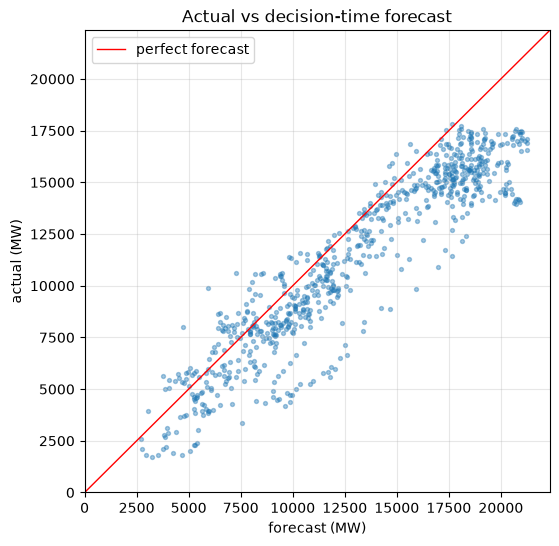

,forecast_level_mw,count,mae_mw,rmse_mw,bias_mw,p10_mw,p90_mw
0,0,13,1199,1293,-596,-1704,1071
1,4000,124,1203,1466,-307,-2098,1291
2,8000,213,1653,2129,-1375,-3635,458
3,12000,126,1529,2127,-1367,-3233,294
4,16000,224,2549,2842,-2546,-4207,-1046
5,20000,44,4641,4798,-4641,-6615,-3352


In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(pairs["forecast_mw"], pairs["actual_mw"], s=8, alpha=0.4)
lim = [0, max(pairs["forecast_mw"].max(), pairs["actual_mw"].max()) * 1.05]
ax.plot(lim, lim, color="red", lw=1, label="perfect forecast")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("forecast (MW)"); ax.set_ylabel("actual (MW)"); ax.legend()
ax.set_title("Actual vs decision-time forecast")
plt.show()

breakdown(pairs, bucket(pairs["forecast_mw"], 4000), "forecast_level_mw")

Below ~8 GW the forecast is nearly unbiased, but above that the actual output falls further and
further short: about −4.6 GW when the forecast is ≥ 20 GW. WINDFOR forecasts generation for all
Power Park Modules, while FUELHH is *metered* output, so the likely explanation is **curtailment**:
at high wind, transmission constraints turn wind farms down. This **cannot be confirmed within the
data scope** (no balancing/constraint data), so it is presented as a hypothesis. Either way, for
a buyer the size of the expected shortfall **depends on how windy the forecast is**.

## 5. Accuracy vs lead time (all forecast vintages)

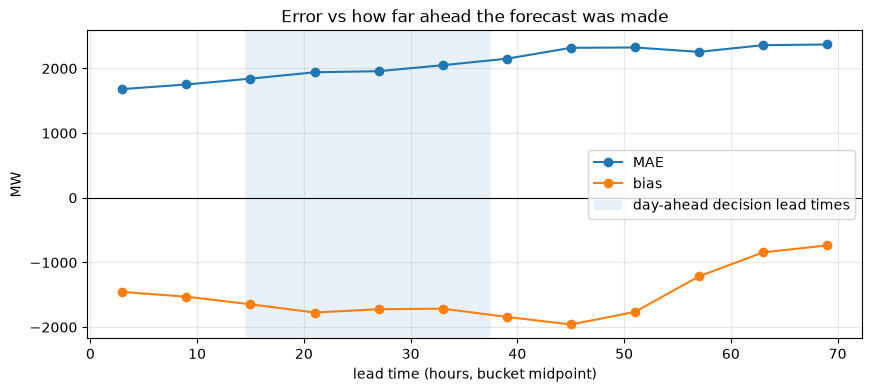

,lead_time_h,count,mae_mw,rmse_mw,bias_mw,p10_mw,p90_mw
0,0,1446,1681,2139,-1455,-3436,361
1,6,1456,1752,2206,-1530,-3556,242
2,12,1470,1842,2313,-1647,-3700,165
3,18,1484,1941,2420,-1774,-3848,101
4,24,1488,1958,2423,-1724,-3916,387
5,30,1488,2050,2524,-1715,-4170,690
6,36,1488,2151,2674,-1842,-4254,545
7,42,1457,2319,2876,-1959,-4564,460
8,48,1209,2325,2904,-1765,-4738,954
9,54,867,2257,2891,-1216,-4471,1770


In [10]:
all_pairs = align(forecasts.rename(columns={"generation_mw": "forecast_mw"}), actuals)
by_lead = breakdown(all_pairs, bucket(all_pairs["lead_time_h"], 6), "lead_time_h")
fig, ax = plt.subplots()
ax.plot(by_lead["lead_time_h"] + 3, by_lead["mae_mw"], marker="o", label="MAE")
ax.plot(by_lead["lead_time_h"] + 3, by_lead["bias_mw"], marker="o", label="bias")
ax.axhline(0, color="black", lw=0.8)
ax.axvspan(14.5, 37.5, alpha=0.1, label="day-ahead decision lead times")
ax.set_xlabel("lead time (hours, bucket midpoint)"); ax.set_ylabel("MW"); ax.legend()
ax.set_title("Error vs how far ahead the forecast was made")
plt.show()
by_lead

Accuracy improves as delivery approaches (MAE ~2.3 GW at 42h+ → ~1.7 GW at 0–6h), but the
**bias stays at about −1.5 to −1.9 GW at every lead time**. It is structural, not a weather-forecast
error that shrinks as forecasts are updated.

## 6. By hour of day and by delivery day

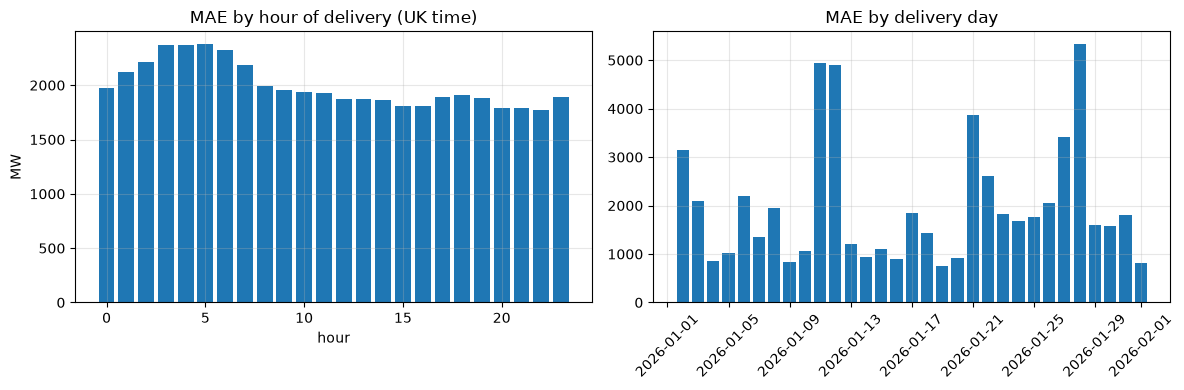

,delivery_day,count,mae_mw,rmse_mw,bias_mw,p10_mw,p90_mw
26,2026-01-28,24,5329,5356,-5329,-5950,-4520
9,2026-01-11,24,4948,5020,-4948,-6031,-3955
10,2026-01-12,24,4908,5197,-4908,-6718,-2188
19,2026-01-21,24,3862,3934,-3862,-4661,-2695
25,2026-01-27,24,3417,3485,-3417,-3999,-2623


In [11]:
by_hour = breakdown(pairs, local_hour(pairs), "hour")
by_day = breakdown(pairs, local_date(pairs), "delivery_day")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(by_hour["hour"], by_hour["mae_mw"]); ax1.set_title("MAE by hour of delivery (UK time)")
ax1.set_xlabel("hour"); ax1.set_ylabel("MW")
ax2.bar(pd.to_datetime(by_day["delivery_day"]), by_day["mae_mw"])
ax2.set_title("MAE by delivery day"); ax2.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
by_day.sort_values("mae_mw", ascending=False).head(5)

## 7. Sensitivity checks

**7a. Alignment method.** WINDFOR is hourly; FUELHH is half-hourly. The app compares each forecast
hour with the half-hour *starting* on the hour. The alternative is the mean of both half-hours in
the hour.

In [12]:
hourly_mean = (
    actuals.assign(start_time=actuals["start_time"].dt.floor("h"))
    .groupby("start_time", as_index=False)["generation_mw"].mean()
)
alt = align(decision_forecasts(forecasts, delivery_days, GATE), hourly_mean)
pd.DataFrame({
    "half-hour on the hour (app)": vars(compute_metrics(pairs)),
    "mean of both half-hours": vars(compute_metrics(alt)),
}).loc[["mae_mw", "rmse_mw", "bias_mw", "wape_pct", "p10_mw", "p90_mw"]]

,half-hour on the hour (app),mean of both half-hours
mae_mw,1996,2013
rmse_mw,2499,2506
bias_mw,-1728,-1730
wape_pct,18,18
p10_mw,-4184,-4144
p90_mw,503,489


**7b. Cutoff time.** How much does the choice of decision time matter? Sweep the cutoff across the
morning of D‑1.

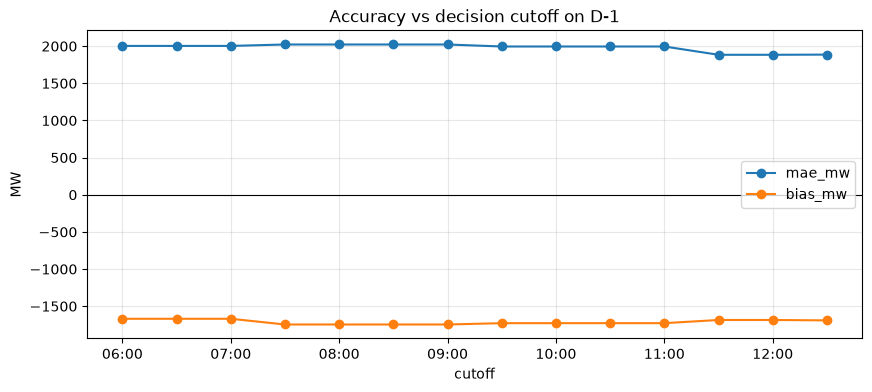

,mae_mw,bias_mw,shortfall_buffer_mw
cutoff,,,
06:00,2003,-1669,4169
06:30,2003,-1669,4169
07:00,2003,-1669,4169
07:30,2022,-1746,4154
08:00,2022,-1746,4154
08:30,2022,-1746,4154
09:00,2022,-1746,4154
09:30,1996,-1728,4184
10:00,1996,-1728,4184


In [13]:
cutoffs = [time(h, mm) for h in range(6, 13) for mm in (0, 30)]
sweep = pd.DataFrame(
    [{"cutoff": f"{c:%H:%M}", **vars(compute_metrics(decision_pairs(c)))} for c in cutoffs]
).set_index("cutoff")
ax = sweep[["mae_mw", "bias_mw"]].plot(marker="o", title="Accuracy vs decision cutoff on D-1")
ax.axhline(0, color="black", lw=0.8); ax.set_ylabel("MW"); plt.show()
sweep[["mae_mw", "bias_mw", "shortfall_buffer_mw"]]

## 8. Conclusions

1. The decision-time forecast is off by ~2 GW per hour on average (~18% WAPE).
2. Errors are **systematically negative**: wind came in ~1.7 GW below forecast on average, and much
   more on windy days. Shortfalls, not surpluses, are the risk to manage.
3. A P10-based buffer of ~4 GW would have covered the wind shortfall in 90% of hours. A
   **level-dependent** buffer would be tighter on calm days and safer on windy ones.
4. Forecast freshness matters much less than the structural bias, and it isn't monotonic in one
   month of data: the 07:30 forecast was slightly *worse* than the 04:30 one. The exception is the
   **11:30 forecast**, which is noticeably better (MAE ~1.88 GW vs ~2.0 GW, buffer ~3.8 vs ~4.2 GW),
   but it arrives **after both day-ahead gates** (09:20 / 09:50). It is only useful for intraday
   re-trading.
5. Results are insensitive to the half-hour alignment choice.

**Caveats:** one month of data (in-sample statistics); wind only (no demand, prices or constraint
data in scope); curtailment is a hypothesis, not verified here.